# Лабораторная работа №2
## Разведочный анализ данных

**Цель работы** — провести первичный аудит двух наборов данных, обработать пропуски и дубликаты, изучить распределения, выявить статистические выбросы и оценить линейные связи между признаками.

**Среда выполнения** — Anaconda Jupyter Notebook, ядро `Python (lab1_terminal)`.

В работе используются **Auto MPG** с преобладанием числовых характеристик автомобилей и **Palmer Penguins** с числовыми измерениями и категориями вида, острова и пола. В лабораторной №1 использовались Iris и Wine. Исходные файлы находятся в `data/`. После запуска графики сохраняются в `figures/`, а результаты анализа — в `outputs/`.

In [1]:
%matplotlib inline

from pathlib import Path
import sys

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

lab_dir = Path.cwd()
if not (lab_dir / "data" / "auto-mpg.data").is_file():
    lab_dir = lab_dir / "lab2"

data_dir = lab_dir / "data"
figures_dir = lab_dir / "figures"
outputs_dir = lab_dir / "outputs"
figures_dir.mkdir(exist_ok=True)
outputs_dir.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", rc={"figure.dpi": 100})
auto_color = "#216C70"
penguins_color = "#6559A5"
species_palette = {"Adelie": "#386CB0", "Chinstrap": "#A95020", "Gentoo": "#2B805A"}

print(f"Python {sys.version.split()[0]}, окружение {Path(sys.prefix).name}")
print(f"pandas {pd.__version__}, Matplotlib {matplotlib.__version__}, seaborn {sns.__version__}")

Python 3.11.16, окружение lab1_terminal
pandas 3.0.5, Matplotlib 3.11.0, seaborn 0.13.2


### Общие методы

- При аудите выводим начало и конец таблицы, её форму, сводку `.info()`, число пропусков и число полных дубликатов. Для числовых признаков считаем среднее, стандартное отклонение, медиану и квартили. Для категориальных — число уникальных значений без пропусков, моду и её частоту. При равных частотах выводим все моды.
- На диаграмме размаха отмечаем значения за границами $Q_1-1{,}5\,IQR$ и $Q_3+1{,}5\,IQR$, где $IQR=Q_3-Q_1$. Отдельно считаем выбросы по признакам и строки, в которых хотя бы один признак выходит за границы. Такие наблюдения сохраняем для анализа.
- Для числовых признаков используем корреляцию Пирсона. Пары упорядочиваем по $|r|$, исключая диагональ и зеркальные повторы.

In [2]:
def audit(frame):
    print(f"Размерность: {frame.shape[0]} строк × {frame.shape[1]} столбцов")
    print("Первые 5 строк")
    display(frame.head())
    print("Последние 5 строк")
    display(frame.tail())
    frame.info()
    display(frame.isna().sum().to_frame("Число пропусков"))
    print(f"Полных дубликатов: {frame.duplicated().sum()}")


def describe_categories(frame, columns):
    rows = []
    for column in columns:
        counts = frame[column].value_counts(dropna=True)
        most_frequent = counts[counts == counts.max()]
        rows.append({
            "Признак": column,
            "Уникальных": frame[column].nunique(),
            "Мода": ", ".join(most_frequent.index.astype(str)),
            "Частота каждой моды": most_frequent.max(),
        })
    return pd.DataFrame(rows).set_index("Признак")


def describe_cleanup(before, after):
    print(f"Строк до очистки: {len(before)}, после: {len(after)}")
    print(f"Пропусков после очистки: {after.isna().sum().sum()}")
    print(f"Полных дубликатов после очистки: {after.duplicated().sum()}")


def show_figure(fig, filename):
    fig.savefig(figures_dir / f"{filename}.png", dpi=130, bbox_inches="tight")
    display(fig)
    plt.close(fig)


def plot_distribution(frame, column, label, color, filename):
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.1), layout="constrained")
    sns.histplot(data=frame, x=column, bins=18, color=color, ax=axes[0])
    sns.kdeplot(data=frame, x=column, fill=True, cut=0, color=color, ax=axes[1])
    sns.violinplot(data=frame, x=column, cut=0, inner="quart", color=color, ax=axes[2])
    axes[0].set(ylabel="Число наблюдений")
    axes[1].set(ylabel="Плотность")
    for ax, title in zip(axes, ["Гистограмма", "Оценка плотности (KDE)", "Скрипичная диаграмма"]):
        ax.set(title=title, xlabel=label)
    show_figure(fig, filename)


def plot_boxplots(frame, labels, color, filename):
    fig, axes = plt.subplots(
        2, 4 if len(labels) > 6 else 3, figsize=(11, 4.2), layout="constrained"
    )
    for ax, (column, label) in zip(axes.flat, labels.items()):
        sns.boxplot(data=frame, x=column, whis=1.5, color=color, ax=ax)
        ax.set(xlabel=label)
    for ax in list(axes.flat)[len(labels):]:
        ax.set_visible(False)
    show_figure(fig, filename)


def summarize_outliers(frame):
    q1 = frame.quantile(0.25)
    q3 = frame.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = frame.lt(lower) | frame.gt(upper)
    summary = pd.DataFrame({
        "Нижняя граница": lower,
        "Верхняя граница": upper,
        "Выбросов": outliers.sum(),
    })
    print(f"Строк с выбросами: {outliers.any(axis=1).sum()} из {len(frame)}")
    display(summary.round(2))
    return summary


def plot_correlations(frame, filename):
    corr = frame.corr(method="pearson")
    pairs = pd.DataFrame(
        [
            (first, second, corr.loc[first, second])
            for index, first in enumerate(corr.columns)
            for second in corr.columns[index + 1:]
        ],
        columns=["Признак 1", "Признак 2", "r"],
    )
    pairs = pairs.sort_values("r", key=lambda values: values.abs(), ascending=False)
    fig, ax = plt.subplots(figsize=(8.3, 5.3), layout="constrained")
    sns.heatmap(
        corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1,
        cbar_kws={"label": "r Пирсона"}, ax=ax,
    )
    ax.tick_params(axis="x", labelrotation=35)
    show_figure(fig, filename)
    display(pairs.head(5).reset_index(drop=True).round(3))
    return corr, pairs

## 1. Auto MPG

Набор описывает экономичность автомобилей в городском цикле и их технические характеристики. `mpg` измеряется в милях на галлон. Чем выше значение, тем большее расстояние автомобиль проходит на том же объёме топлива. Локальный файл `auto-mpg.data` содержит исходную таблицу без заголовка. [R. Quinlan, Auto MPG, UCI Machine Learning Repository (CC BY 4.0)](https://doi.org/10.24432/C5859H).

### 1.1. Первичный аудит

In [3]:
auto_labels = {
    "mpg": "Экономичность, миль/галлон",
    "cylinders": "Количество цилиндров",
    "displacement": "Объём двигателя, куб. дюймы",
    "horsepower": "Мощность, л. с.",
    "weight": "Масса, фунты",
    "acceleration": "Время разгона, с",
    "model_year": "Модельный год (две цифры)",
}
auto_categorical = ["origin", "car_name"]

auto_raw = pd.read_csv(
    data_dir / "auto-mpg.data",
    sep=r"\s+",
    header=None,
    names=[*auto_labels, *auto_categorical],
    na_values="?",
)
audit(auto_raw)

Размерность: 398 строк × 9 столбцов
Первые 5 строк


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


Последние 5 строк


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
393,27.0,4,140.0,86.0,2790.0,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52.0,2130.0,24.6,82,2,vw pickup
395,32.0,4,135.0,84.0,2295.0,11.6,82,1,dodge rampage
396,28.0,4,120.0,79.0,2625.0,18.6,82,1,ford ranger
397,31.0,4,119.0,82.0,2720.0,19.4,82,1,chevy s-10


<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    str    
dtypes: float64(5), int64(3), str(1)
memory usage: 28.1 KB


,Число пропусков
mpg,0
cylinders,0
displacement,0
horsepower,6
weight,0
acceleration,0
model_year,0
origin,0
car_name,0


Полных дубликатов: 0


В таблице 398 строк и 9 столбцов. Измерения и модельный год представлены числами. В столбце `origin` числа кодируют категории происхождения, поэтому преобразуем его в категориальный тип перед анализом и исключим из корреляционной матрицы. Названия моделей в `car_name` используем как текстовые метки. Знак `?` в поле мощности интерпретируется как пропуск уже при чтении файла.

### 1.2. Описательные статистики и очистка

In [4]:
auto_typed = auto_raw.astype({"origin": "category", "car_name": "string"})
display(auto_typed[list(auto_labels)].describe().T.rename(columns={"50%": "Медиана"}).round(2))
display(describe_categories(auto_typed, auto_categorical))

auto = auto_typed.drop_duplicates().copy()
horsepower_median = auto["horsepower"].median()
auto["horsepower"] = auto["horsepower"].fillna(horsepower_median)
print(f"Медиана для заполнения пропусков мощности: {horsepower_median:g} л. с.")
describe_cleanup(auto_raw, auto)

,count,mean,std,min,25%,Медиана,75%,max
mpg,398.0,23.51,7.82,9.0,17.50,23.0,29.00,46.6
cylinders,398.0,5.45,1.70,3.0,4.00,4.0,8.00,8.0
displacement,398.0,193.43,104.27,68.0,104.25,148.5,262.00,455.0
horsepower,392.0,104.47,38.49,46.0,75.00,93.5,126.00,230.0
weight,398.0,2970.42,846.84,1613.0,2223.75,2803.5,3608.00,5140.0
acceleration,398.0,15.57,2.76,8.0,13.82,15.5,17.18,24.8
model_year,398.0,76.01,3.70,70.0,73.00,76.0,79.00,82.0


,Уникальных,Мода,Частота каждой моды
Признак,,,
origin,3,1,249
car_name,305,ford pinto,6


Медиана для заполнения пропусков мощности: 93.5 л. с.
Строк до очистки: 398, после: 398
Пропусков после очистки: 0
Полных дубликатов после очистки: 0


Все шесть пропусков находятся в `horsepower`. Подстановка медианы **93,5 л. с.** сохраняет все 398 строк и слабо зависит от крайних значений. Полных дубликатов нет. Одно название может встречаться у автомобилей с разными характеристиками и годами выпуска.

### 1.3. Распределения и статистические выбросы

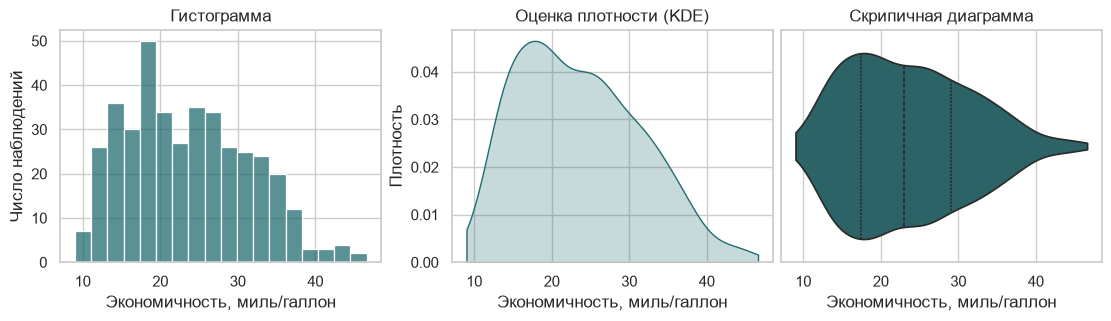

In [5]:
plot_distribution(auto, "mpg", auto_labels["mpg"], auto_color, "auto_mpg_distribution")

- **Гистограмма.** Самый высокий столбец приходится примерно на интервал 17–19 миль/галлон. Наблюдений выше 38 миль/галлон мало.
- **KDE.** Основная плотность сосредоточена в районе 20 миль/галлон, правый хвост тянется к высоким значениям.
- **Скрипичная диаграмма.** Медиана равна 23,0 миль/галлон. Средние 50% наблюдений лежат между 17,5 и 29,0, а узкая правая часть показывает низкую плотность высоких значений.

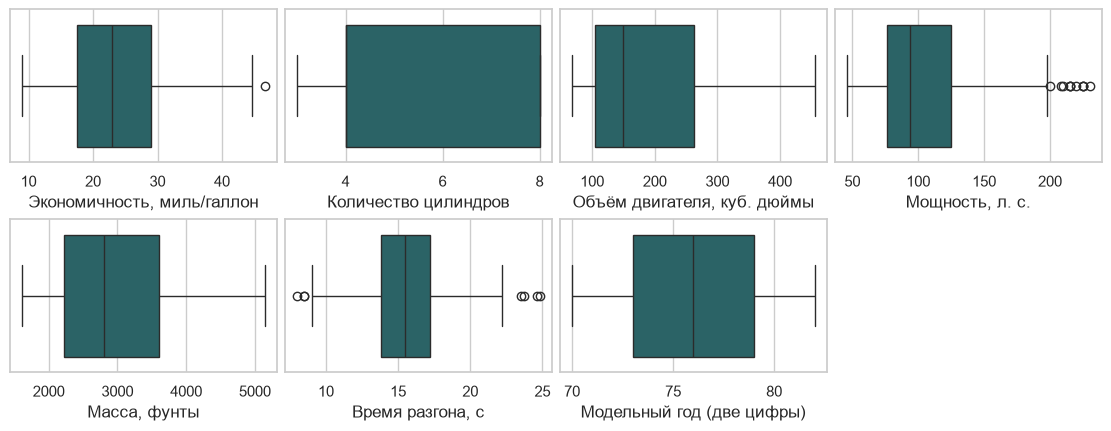

Строк с выбросами: 18 из 398


,Нижняя граница,Верхняя граница,Выбросов
mpg,0.25,46.25,1
cylinders,-2.00,14.00,0
displacement,-132.38,498.62,0
horsepower,2.50,198.50,11
weight,147.38,5684.38,0
acceleration,8.80,22.20,7
model_year,64.00,88.00,0


In [6]:
plot_boxplots(auto, auto_labels, auto_color, "auto_mpg_boxplots")
auto_iqr = summarize_outliers(auto[list(auto_labels)])

**Диаграммы размаха.** За границами $1{,}5\,IQR$ находятся 11 значений мощности, 7 значений времени разгона и 1 значение экономичности. Это 18 разных строк из 398 (4,5%). У массы, объёма двигателя, числа цилиндров и модельного года выбросов по этому правилу нет. Крайние значения могут соответствовать реальным автомобилям, поэтому оставляем эти строки в таблице.

### 1.4. Корреляции и зависимости

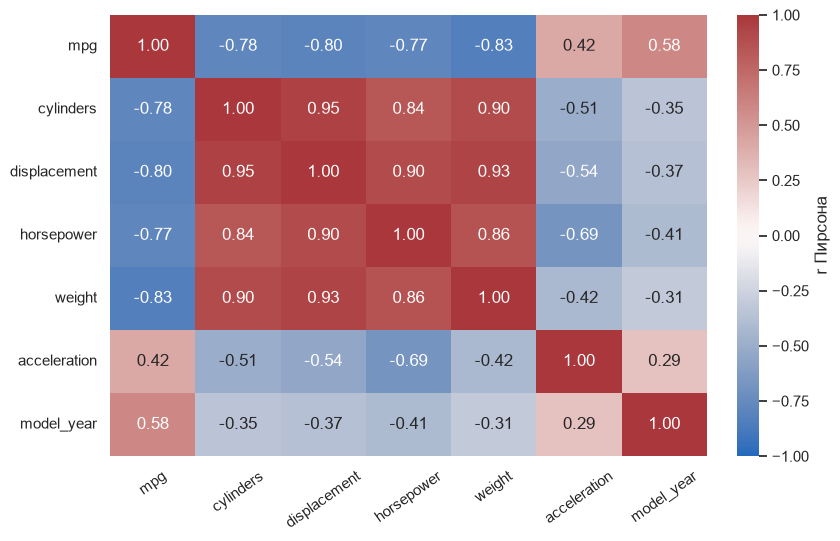

,Признак 1,Признак 2,r
0,cylinders,displacement,0.951
1,displacement,weight,0.933
2,cylinders,weight,0.896
3,displacement,horsepower,0.896
4,horsepower,weight,0.862


In [7]:
auto_corr, auto_pairs = plot_correlations(auto[list(auto_labels)], "auto_mpg_correlations")

**Тепловая карта.** Наибольшая по модулю связь обнаружена между числом цилиндров и объёмом двигателя ($r=0{,}951$). Объём двигателя также тесно связан с массой ($r=0{,}933$). Среди связей с `mpg` наиболее сильная наблюдается для массы ($r=-0{,}832$).

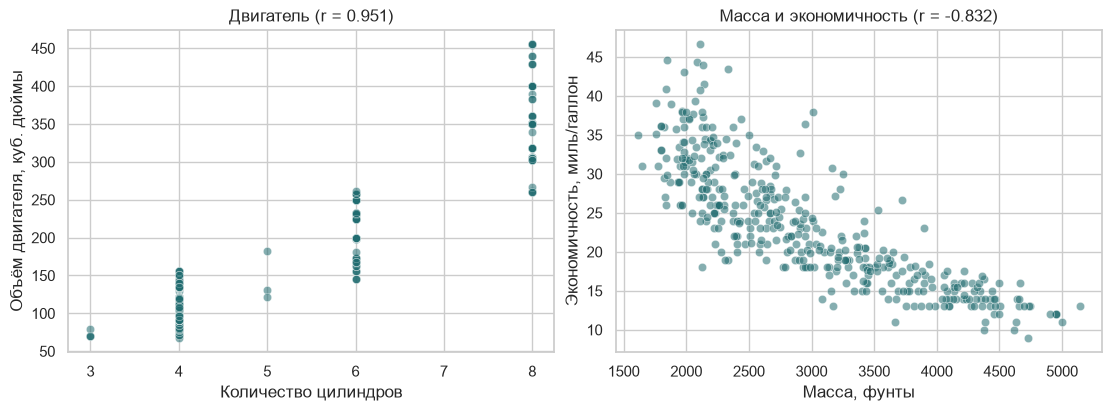

In [8]:
auto_x, auto_y = auto_pairs.iloc[0][["Признак 1", "Признак 2"]]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
sns.scatterplot(data=auto, x=auto_x, y=auto_y, color=auto_color, alpha=0.55, ax=axes[0])
sns.scatterplot(data=auto, x="weight", y="mpg", color=auto_color, alpha=0.55, ax=axes[1])
axes[0].set(
    xlabel=auto_labels[auto_x], ylabel=auto_labels[auto_y],
    title=f"Двигатель (r = {auto_corr.loc[auto_x, auto_y]:.3f})",
)
axes[1].set(
    xlabel=auto_labels["weight"], ylabel=auto_labels["mpg"],
    title=f"Масса и экономичность (r = {auto_corr.loc['weight', 'mpg']:.3f})",
)
show_figure(fig, "auto_mpg_scatter")

- **Число цилиндров и объём двигателя.** Точки образуют вертикальные полосы, поскольку число цилиндров дискретно. У 8-цилиндровых автомобилей объём двигателя обычно больше, чем у 4-цилиндровых.
- **Масса и экономичность.** Облако точек наклонено вниз. В выборке тяжёлые автомобили обычно проезжают меньше миль на галлон. Разброс `mpg` особенно заметен у лёгких автомобилей.

## 2. Palmer Penguins

Упрощённый набор содержит измерения пингвинов трёх видов с островов архипелага Палмер. Локальный файл `penguins.csv` взят из пакета palmerpenguins. [A. M. Horst, A. P. Hill, K. B. Gorman, palmerpenguins (CC0)](https://allisonhorst.github.io/palmerpenguins/).

### 2.1. Первичный аудит

In [9]:
penguin_labels = {
    "bill_length_mm": "Длина клюва, мм",
    "bill_depth_mm": "Глубина клюва, мм",
    "flipper_length_mm": "Длина ласта, мм",
    "body_mass_g": "Масса, г",
    "year": "Год наблюдения",
}
penguin_categorical = ["species", "island", "sex"]

penguins_raw = pd.read_csv(data_dir / "penguins.csv")
audit(penguins_raw)

Размерность: 344 строк × 8 столбцов
Первые 5 строк


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


Последние 5 строк


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009
343,Chinstrap,Dream,50.2,18.7,198.0,3775.0,female,2009


<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB


,Число пропусков
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11
year,0


Полных дубликатов: 0


Исходная таблица содержит 344 строки и 8 столбцов. `species`, `island` и `sex` обозначают категории. Длина ласта и масса содержат целые измерения и прочитаны как вещественные из-за пропусков. После очистки преобразуем их в целочисленный тип. Длина и глубина клюва содержат дробные значения, а `year` — целый год наблюдения.

### 2.2. Описательные статистики и очистка

In [10]:
penguins_typed = penguins_raw.astype(dict.fromkeys(penguin_categorical, "category"))
display(
    penguins_typed[list(penguin_labels)].describe().T
    .rename(columns={"50%": "Медиана"}).round(2)
)
display(describe_categories(penguins_typed, penguin_categorical))

penguins = (
    penguins_typed.drop_duplicates()
    .dropna()
    .astype({"flipper_length_mm": "int64", "body_mass_g": "int64"})
)
describe_cleanup(penguins_raw, penguins)
display(pd.crosstab(penguins["species"], penguins["island"]))

,count,mean,std,min,25%,Медиана,75%,max
bill_length_mm,342.0,43.92,5.46,32.1,39.22,44.45,48.5,59.6
bill_depth_mm,342.0,17.15,1.97,13.1,15.60,17.30,18.7,21.5
flipper_length_mm,342.0,200.92,14.06,172.0,190.00,197.00,213.0,231.0
body_mass_g,342.0,4201.75,801.95,2700.0,3550.00,4050.00,4750.0,6300.0
year,344.0,2008.03,0.82,2007.0,2007.00,2008.00,2009.0,2009.0


,Уникальных,Мода,Частота каждой моды
Признак,,,
species,3,Adelie,152
island,3,Biscoe,168
sex,2,male,168


Строк до очистки: 344, после: 333
Пропусков после очистки: 0
Полных дубликатов после очистки: 0


island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,55,47
Chinstrap,0,68,0
Gentoo,119,0,0


Пол указан не у 11 пингвинов. В двух из этих строк отсутствуют и все четыре измерения. Для анализа полных наблюдений удаляем 11 строк (3,2%), остаются **333 строки**. Полных дубликатов нет. В очищенных данных представлены три вида. Все наблюдения Gentoo относятся к острову Biscoe, все Chinstrap — к Dream, а Adelie встречается на всех трёх островах. При сравнении островов нужно учитывать различия в видовом составе.

### 2.3. Распределения и статистические выбросы

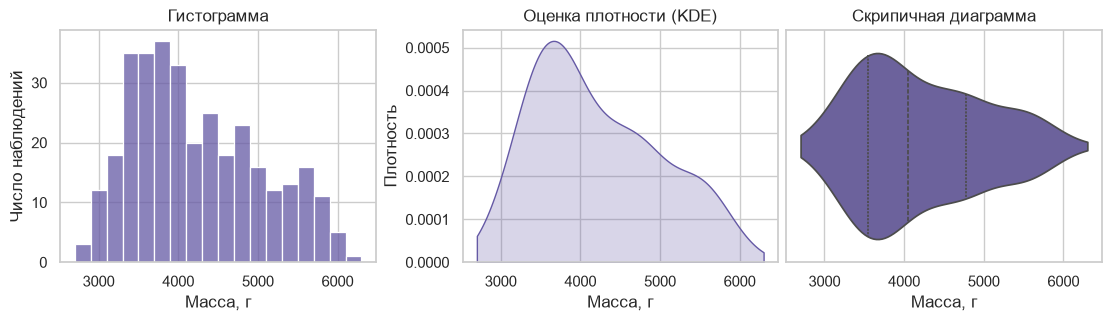

In [11]:
plot_distribution(penguins, "body_mass_g", penguin_labels["body_mass_g"], penguins_color,
                  "penguins_mass_distribution")

- **Гистограмма.** Высокие столбцы сосредоточены между 3,3 и 4,1 кг, а в районе 4,9–5,1 кг заметно второе скопление.
- **KDE.** Сглаживание показывает пик около 3,7 кг. Правее 4,5 кг плотность снижается более плавно.
- **Скрипичная диаграмма.** Медиана общей выборки — 4050 г, межквартильный интервал — от 3550 до 4775 г. Правая часть диаграммы шире около 5 кг, чем у верхней границы наблюдаемых значений.

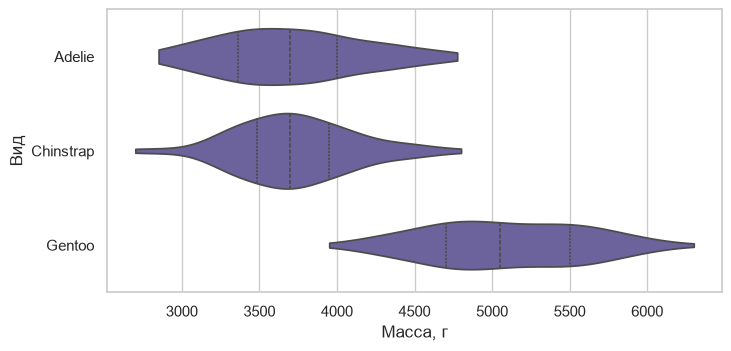

,"Медиана массы, г"
species,
Adelie,3700.0
Chinstrap,3700.0
Gentoo,5050.0


In [12]:
fig, ax = plt.subplots(figsize=(7.2, 3.4), layout="constrained")
sns.violinplot(
    data=penguins, x="body_mass_g", y="species",
    color=penguins_color, inner="quart", cut=0, ax=ax,
)
ax.set(xlabel=penguin_labels["body_mass_g"], ylabel="Вид")
show_figure(fig, "penguins_mass_by_species")
display(penguins.groupby("species", observed=True)["body_mass_g"].median().to_frame("Медиана массы, г"))

**Масса по видам.** Медиана Gentoo составляет 5050 г, у Adelie и Chinstrap — по 3700 г. Все наблюдения с массой от 5000 г относятся к Gentoo. Распределения Adelie и Chinstrap заметно перекрываются.

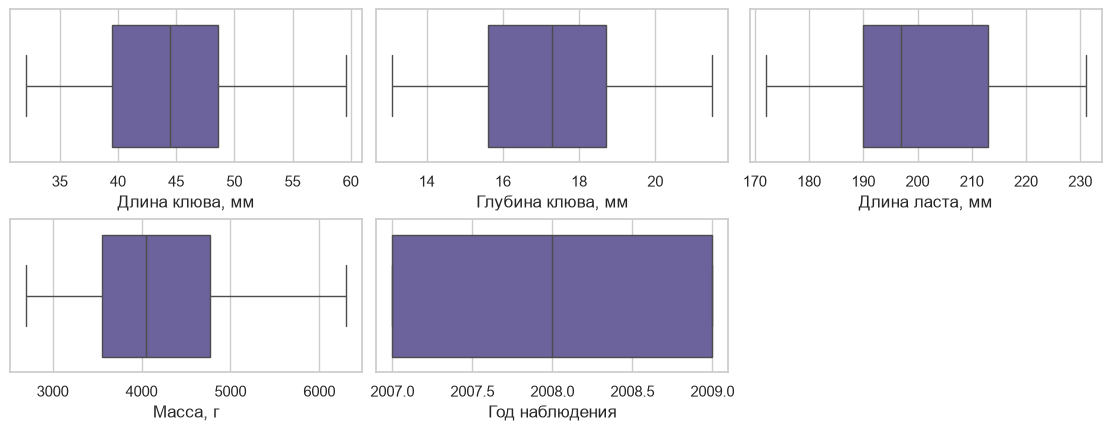

Строк с выбросами: 0 из 333


,Нижняя граница,Верхняя граница,Выбросов
bill_length_mm,25.85,62.25,0
bill_depth_mm,10.95,23.35,0
flipper_length_mm,155.50,247.50,0
body_mass_g,1712.50,6612.50,0
year,2004.00,2012.00,0


In [13]:
plot_boxplots(penguins, penguin_labels, penguins_color, "penguins_boxplots")
penguins_iqr = summarize_outliers(penguins[list(penguin_labels)])

**Диаграммы размаха.** Ни одна из 333 строк не выходит за общие границы $1{,}5\,IQR$ по пяти числовым столбцам. Границы рассчитаны для объединённой выборки. Диапазоны внутри отдельных видов могут отличаться.

### 2.4. Корреляции и зависимости

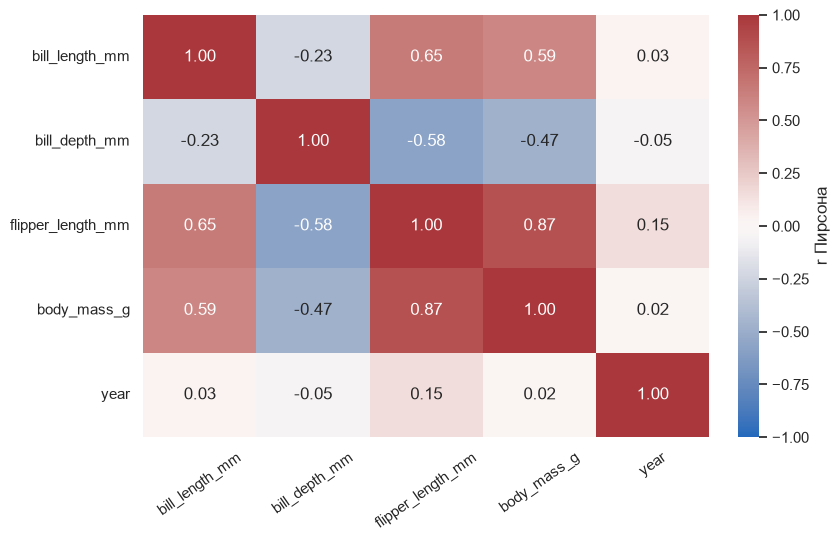

,Признак 1,Признак 2,r
0,flipper_length_mm,body_mass_g,0.873
1,bill_length_mm,flipper_length_mm,0.653
2,bill_length_mm,body_mass_g,0.589
3,bill_depth_mm,flipper_length_mm,-0.578
4,bill_depth_mm,body_mass_g,-0.472


In [14]:
penguins_corr, penguins_pairs = plot_correlations(
    penguins[list(penguin_labels)], "penguins_correlations"
)

**Тепловая карта.** Наиболее сильная линейная связь наблюдается между длиной ласта и массой ($r=0{,}873$). Длина клюва также связана с длиной ласта ($r=0{,}653$). Связи измерений с годом наблюдения слабые, наибольшее $|r|$ равно 0,151.

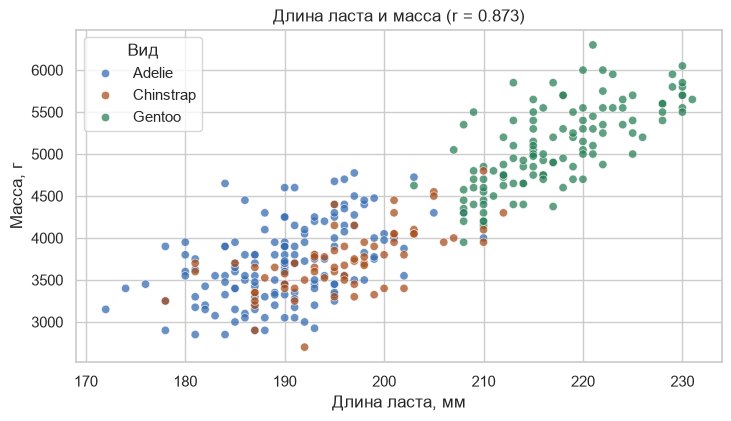

,r внутри вида
Adelie,0.465
Chinstrap,0.642
Gentoo,0.711


In [15]:
penguin_x, penguin_y = penguins_pairs.iloc[0][["Признак 1", "Признак 2"]]
fig, ax = plt.subplots(figsize=(7.2, 4.1), layout="constrained")
sns.scatterplot(
    data=penguins, x=penguin_x, y=penguin_y, hue="species",
    palette=species_palette, alpha=0.75, ax=ax,
)
ax.set(
    xlabel=penguin_labels[penguin_x], ylabel=penguin_labels[penguin_y],
    title=f"Длина ласта и масса (r = {penguins_corr.loc[penguin_x, penguin_y]:.3f})",
)
ax.legend(title="Вид")
show_figure(fig, "penguins_scatter")

within_species = {
    species: group[penguin_x].corr(group[penguin_y])
    for species, group in penguins.groupby("species", observed=True)
}
display(pd.Series(within_species, name="r внутри вида").round(3).to_frame())

**Диаграмма рассеяния.** Gentoo чаще находятся в правой верхней области: у них длиннее ласты и больше масса. Внутри каждого вида связь остаётся положительной ($r$ от 0,465 до 0,711), но слабее общей. Различия между видами усиливают общий коэффициент.

## 3. Сохранение результатов

In [16]:
for name, clean, corr, iqr in [
    ("auto_mpg", auto, auto_corr, auto_iqr),
    ("penguins", penguins, penguins_corr, penguins_iqr),
]:
    clean.to_csv(outputs_dir / f"{name}_clean.csv", index=False)
    corr.to_csv(outputs_dir / f"{name}_correlations.csv", float_format="%.6f")
    iqr.to_csv(outputs_dir / f"{name}_iqr.csv", float_format="%.6f")

print("Сохранены очищенные таблицы, матрицы корреляций, границы IQR и графики обоих наборов.")

Сохранены очищенные таблицы, матрицы корреляций, границы IQR и графики обоих наборов.


## 4. Выводы для защиты

| Набор | Очистка | Сильная линейная связь | Аномалии по правилу IQR |
| --- | --- | --- | --- |
| Auto MPG | Сохранились 398 строк. Шесть пропусков мощности заполнены медианой, полных дубликатов нет. | Число цилиндров и объём двигателя ($r=0{,}951$). Экономичность снижается с ростом массы ($r=-0{,}832$). | 18 строк из 398, чаще всего по мощности. |
| Palmer Penguins | Из 344 строк осталось 333. Удалены 11 неполных наблюдений, полных дубликатов нет. | Длина ласта и масса ($r=0{,}873$). Связь слабее при расчёте отдельно для каждого вида. | 0 строк из 333 при общих границах для объединённой выборки. |

Для дальнейшего моделирования в Auto MPG происхождение можно закодировать как категорию, а медиану мощности вычислять на обучающей выборке. Перед включением числа цилиндров и объёма двигателя в линейную модель стоит оценить мультиколлинеарность. В Palmer Penguins при анализе массы полезно учитывать вид, а при сравнении островов — видовой состав. Если задача моделирования потребует другой обработки пропусков, можно вернуться к исходной таблице.